# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import NaSCTG2Dataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/nasc_tg2/train-00000-of-00001-c90f4eba437ea4db.parquet"
}
dataset = NaSCTG2Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 20000


## Show images from the dataset

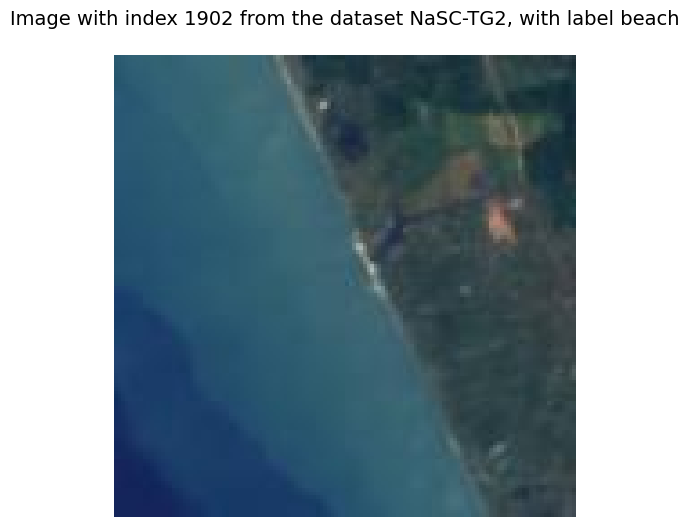

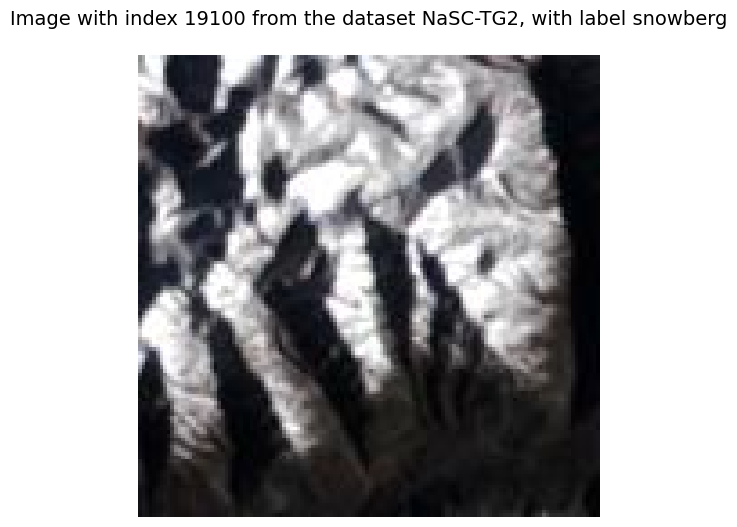

In [8]:
fig1 = dataset.show_image(1902)
fig2 = dataset.show_image(19100);

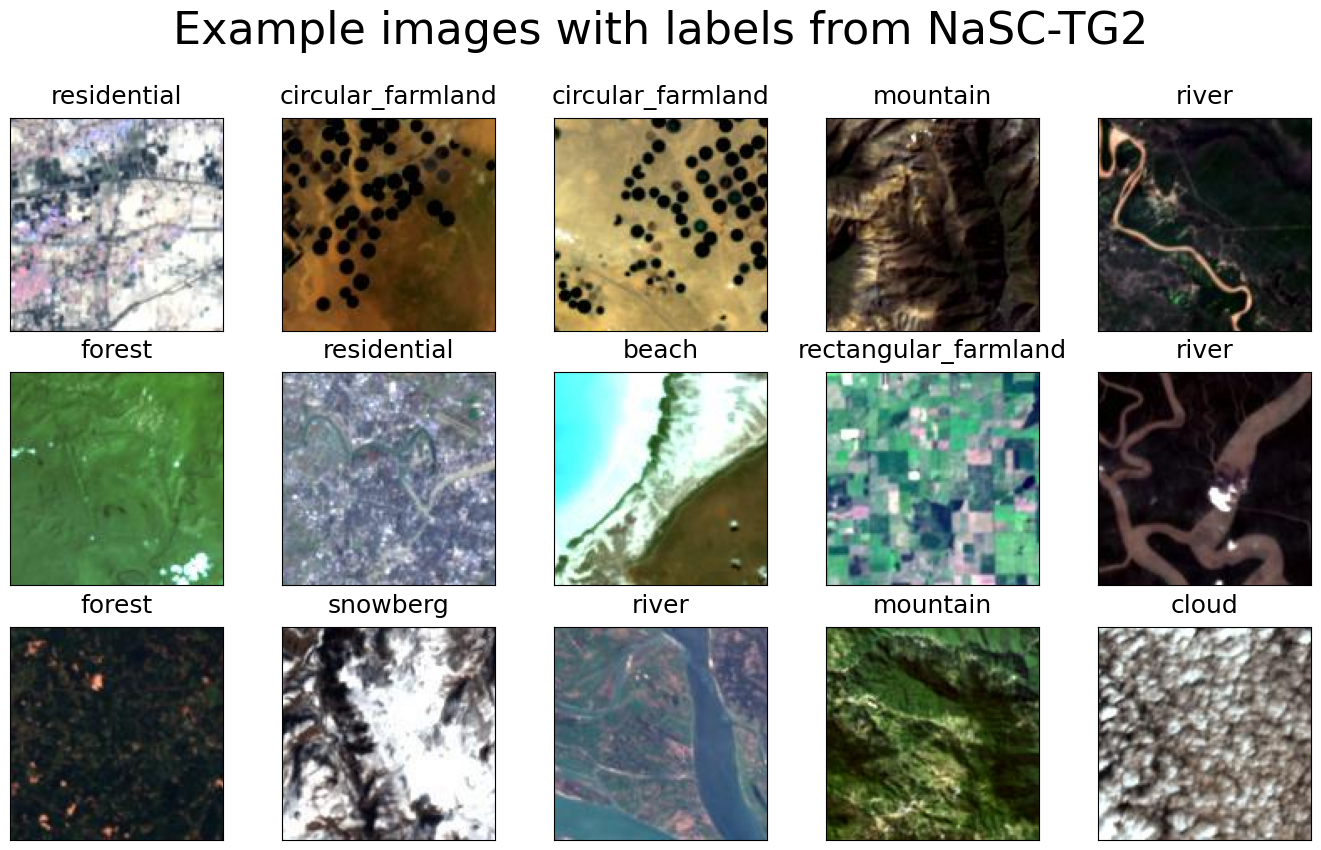

In [9]:
fig3 = dataset.show_batch(15);

## Inspect the data

In [6]:
dataset.data_distribution_table()

,Label,Count
0,beach,2000
1,circular_farmland,2000
2,cloud,2000
3,desert,2000
4,forest,2000
5,mountain,2000
6,rectangular_farmland,2000
7,residential,2000
8,river,2000
9,snowberg,2000


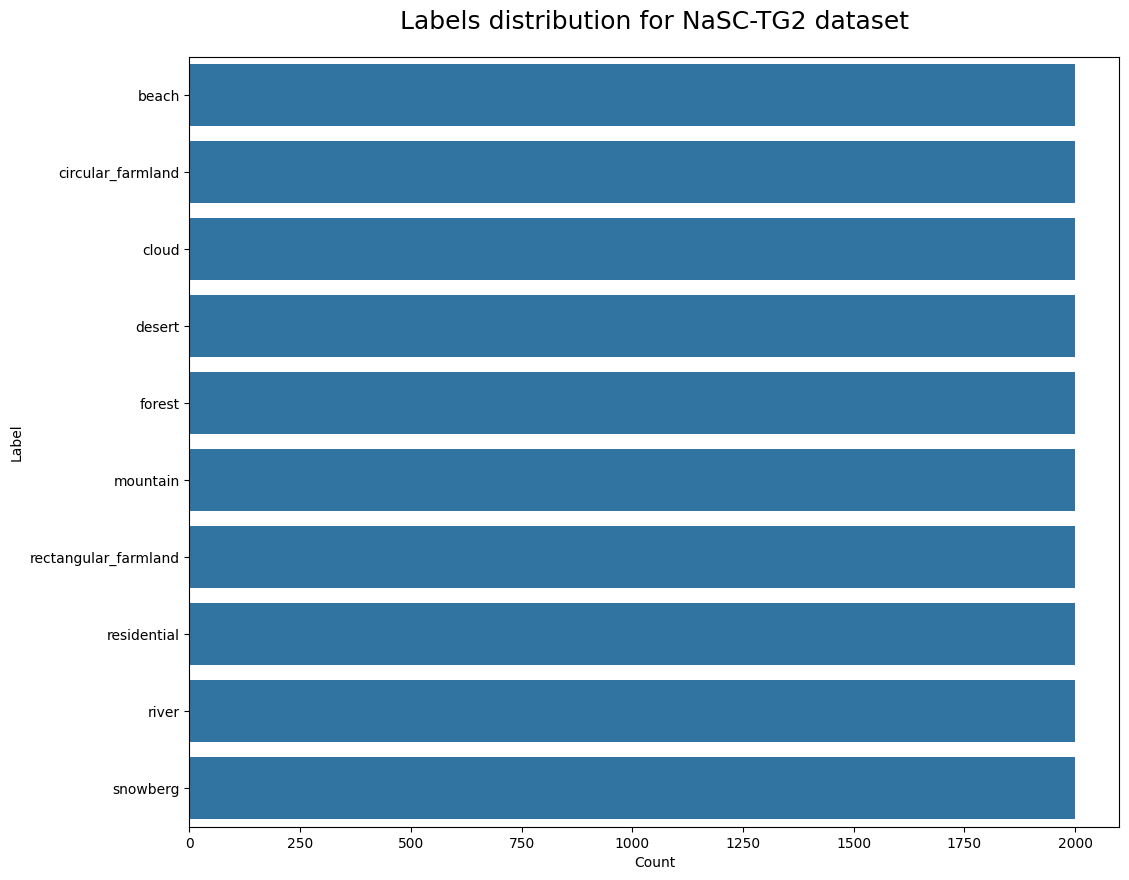

In [7]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/nasc_tg2/train-00000-of-00001-c90f4eba437ea4db.parquet",
    "csv_file": "./data/nasc_tg2/nasc_tg2_train.csv",
}

train_dataset = NaSCTG2Dataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/nasc_tg2/train-00000-of-00001-c90f4eba437ea4db.parquet",
    "csv_file": "./data/nasc_tg2/nasc_tg2_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = NaSCTG2Dataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(16000, 2000)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/nasc-tg2/"
model_config = {
    "num_classes": 10, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-08-26 10:12:34,340 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-08-26 10:12:34,514 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [12]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-07-03 09:03:52,845 INFO Starting training.
training: 100%|██████████| 500/500 [02:04<00:00,  4.02it/s]
2025-07-03 09:05:57,370 INFO epoch: 1, time: 125, loss:  0.20073
testing on train set: 100%|██████████| 500/500 [00:44<00:00, 11.35it/s]
2025-07-03 09:06:43,555 INFO Accuracy:0.9533125, Precision Micro:0.9533125, Precision Macro:0.9641991395398609, Precision Weighted:0.9641991395398608, Precision per Class:[0.99745547 0.99937304 1.         0.9987253  0.994375   0.9894081
 0.99004975 0.99500312 0.956231   0.7213706 ], Recall Micro:0.9533125, Recall Macro:0.9533125, Recall Weighted:0.9533125000000001, Recall per Class:[0.98     0.99625  0.616875 0.979375 0.994375 0.9925   0.995    0.995625
 0.983125 1.      ], F1_score Micro:0.9533124999999995, F1_score Macro:0.9519247256356959, F1_score Weighted:0.951924725635696, F1_score per Class:[0.98865069 0.99780908 0.763046   0.98895551 0.994375   0.99095164
 0.9925187  0.99531396 0.96949153 0.83813515]
testing on validation set: 100%|█████

0.010113359957234934

## Test the model

In [ ]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/nasc_tg2/train-00000-of-00001-c90f4eba437ea4db.parquet",
    "csv_file": "./data/nasc_tg2/nasc_tg2_test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = NaSCTG2Dataset(test_dataset_config)
model_path = "./data/experiments/nasc-tg2/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-07-03 09:40:52,898 INFO Loading checkpoint /home/dragik/alice/FAIR_EO/experiments/nasc-tg2/checkpoint.pth.tar
2025-07-03 09:40:53,243 INFO Loaded checkpoint /home/dragik/alice/FAIR_EO/experiments/nasc-tg2/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 125/125 [00:06<00:00, 19.87it/s]


[{'Accuracy': 0.992},
 {'Precision Micro': 0.992,
  'Precision Macro': 0.9920252600566422,
  'Precision Weighted': 0.9920252600566422,
  'Precision per Class': array([0.98039216, 0.99502488, 0.99502488, 1.        , 1.        ,
         0.99497487, 0.9800995 , 0.99009901, 0.98963731, 0.995     ])},
 {'Recall Micro': 0.992,
  'Recall Macro': 0.9920000000000002,
  'Recall Weighted': 0.9920000000000001,
  'Recall per Class': array([1.   , 1.   , 1.   , 0.995, 1.   , 0.99 , 0.985, 1.   , 0.955,
         0.995])},
 {'F1_score Micro': 0.9919999999999994,
  'F1_score Macro': 0.9919665110708967,
  'F1_score Weighted': 0.9919665110708967,
  'F1_score per Class': array([0.99009901, 0.99750623, 0.99750623, 0.99749373, 1.        ,
         0.9924812 , 0.98254364, 0.99502488, 0.97201018, 0.995     ])}]

## Predictions

2025-08-26 10:13:33,565 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/nasc-tg2/checkpoint.pth.tar
2025-08-26 10:13:33,908 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/nasc-tg2/checkpoint.pth.tar at epoch 11


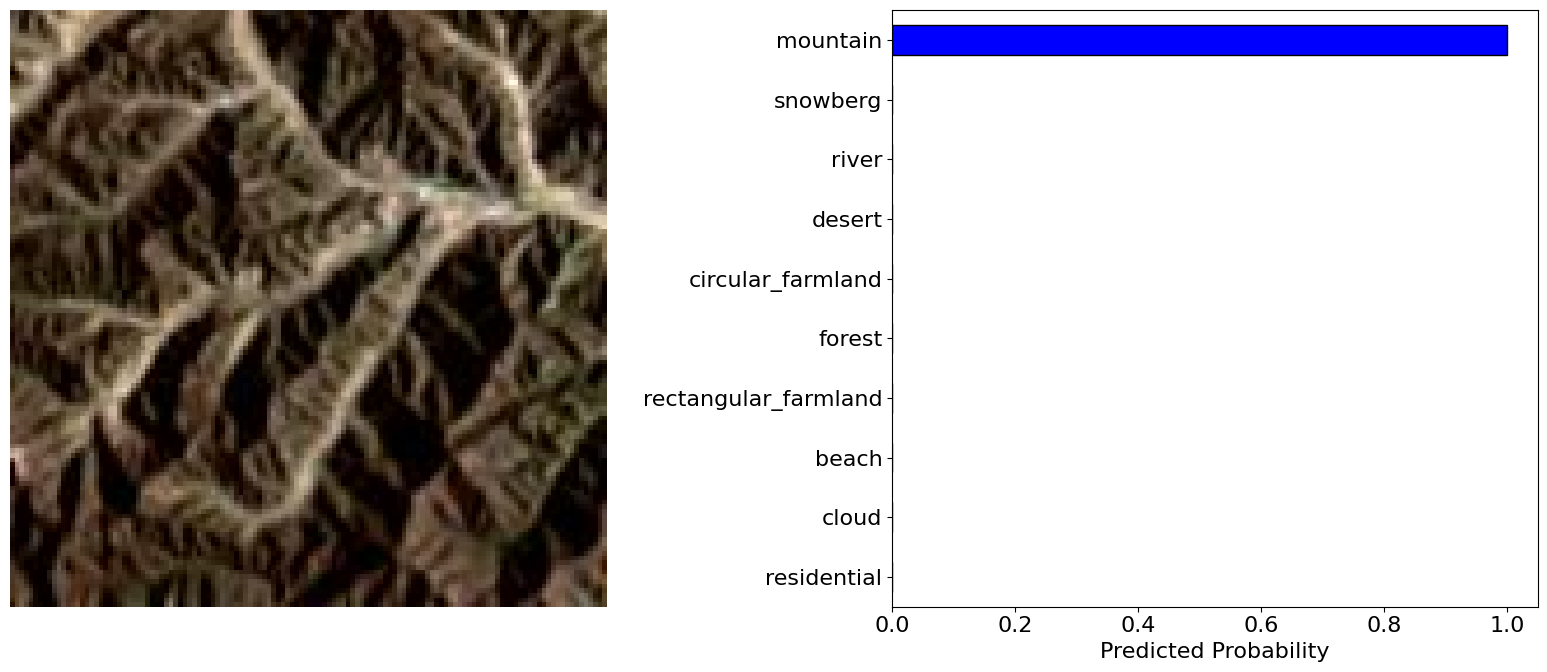

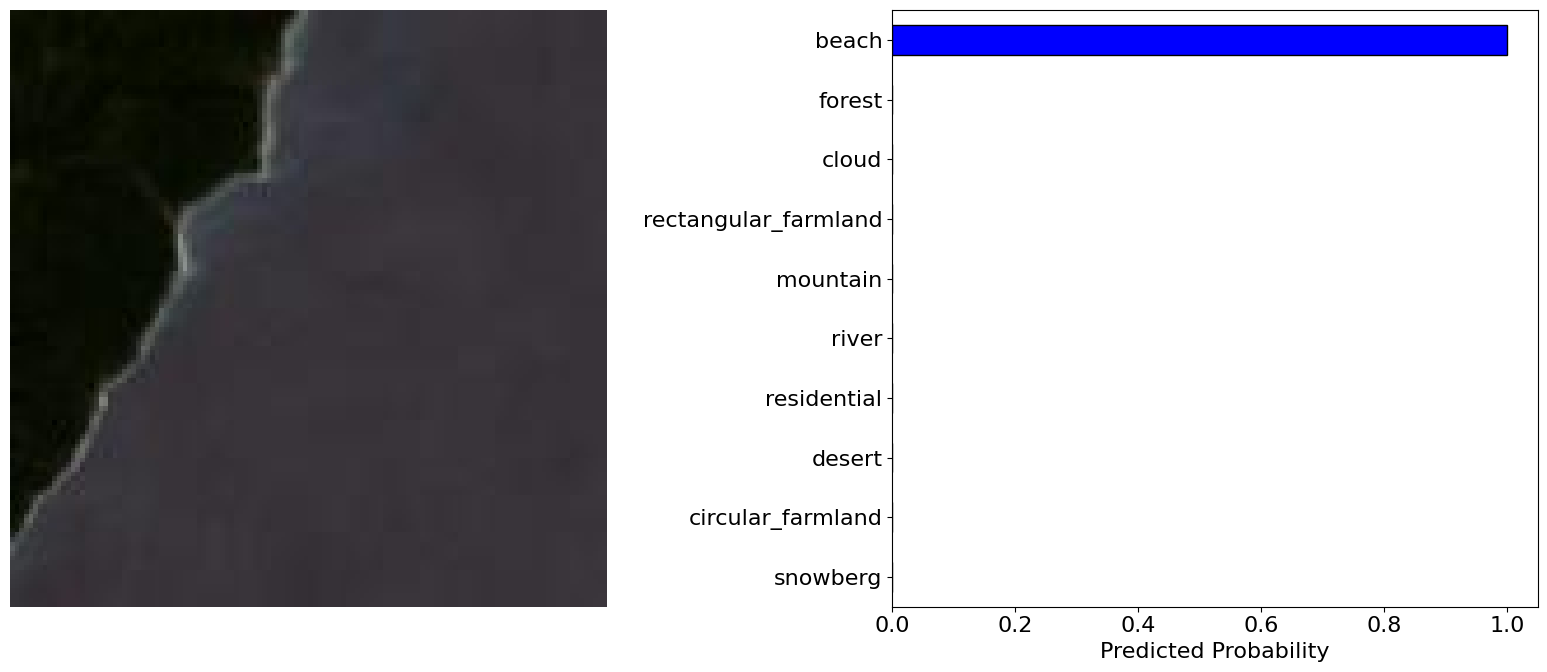

In [ ]:
labels = ["beach", "circular_farmland", "cloud", "desert", "forest", 
        "mountain", "rectangular_farmland", "residential", "river", "snowberg"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/nasc-tg2/checkpoint.pth.tar"
model.load_model(model_path)

data_dir = "./data/nasc_tg2/train-00000-of-00001-c90f4eba437ea4db.parquet"
csv_file = "./data/nasc_tg2/nasc_tg2_test.csv"

# Read parquet into DataFrame
df = pd.read_parquet(data_dir)

idx_df = pd.read_csv(csv_file, header=None, names=['index', 'label'])
# Filter parquet df to only rows with those indexes
df = df.iloc[idx_df['index'].values]

data = []
for _, row in df.iterrows():
        # row['image'] contains a dict with 'bytes'
        img_bytes = row['image']['bytes']  # raw image bytes
        data.append((img_bytes))

# get raw bytes
img_bytes = data[0]
# load image from bytes directly
image = np.asarray(Image.open(io.BytesIO(img_bytes)))
fig = model.predict_image(image, labels, transform)

# get raw bytes
img_bytes = data[10]
# load image from bytes directly
image = np.asarray(Image.open(io.BytesIO(img_bytes)))
fig = model.predict_image(image, labels, transform)